# Asteroid Albedo Classification and Physical Characterization

**Project 5: Finding Asteroid Families with Unsupervised Learning**

**Team:** Akriti Mahto, Sendhil Damodaran, Nikhil Pillai

## 1. Overview

This notebook investigates asteroid albedo using orbital characteristics, absolute magnitude, and spectral classifications obtained from the NASA/JPL Small-Body Database.

### Objectives

- **FR-11:** Define albedo classification targets.
- **FR-12:** Develop supervised classification models.
- **FR-13:** Evaluate and compare model performance.
- **FR-14:** Analyze albedo across spectral complexes.
- **FR-15:** Compare albedo across orbital populations.
- **H4:** Investigate albedo uniformity within asteroid families.

## 2. Data Collection

Asteroid data is retrieved from the NASA/JPL Small-Body Database (SBDB) using its public API.

The initial dataset contains 825,292 main-belt asteroids, including orbital parameters, absolute magnitude, geometric albedo, and spectral classifications.

**Source:** https://ssd.jpl.nasa.gov/tools/sbdb_query.html

In [47]:

import requests
import pandas as pd

url = "https://ssd-api.jpl.nasa.gov/sbdb_query.api"

params = {
    "fields": "pdes,full_name,class,a,e,i,H,albedo,spec_B,spec_T",
    "sb-kind": "a",
    "sb-ns": "n",
    "sb-class": "MBA",
    "sort": "pdes"
}

# Find the total number of matching asteroids
response = requests.get(url, params=params, timeout=120)
response.raise_for_status()
total = int(response.json()["count"])

print("Total matching asteroids:", total)

# Download all records in batches
all_rows = []
batch_size = 10000

for start in range(0, total, batch_size):
    batch_params = {
        **params,
        "limit": batch_size,
        "limit-from": start
    }

    response = requests.get(
        url, params=batch_params, timeout=120
    )
    response.raise_for_status()

    result = response.json()
    all_rows.extend(result.get("data", []))

    print(f"Downloaded {len(all_rows):,} of {total:,}")

df_full = pd.DataFrame(
    all_rows, columns=result["fields"]
)

df_full.to_csv("sbdb_full_raw.csv", index=False)

print("\nFinal shape:", df_full.shape)
print("Albedo available:",
      df_full["albedo"].notna().sum())


Total matching asteroids: 825292
Downloaded 10,000 of 825,292
Downloaded 20,000 of 825,292
Downloaded 30,000 of 825,292
Downloaded 40,000 of 825,292
Downloaded 50,000 of 825,292
Downloaded 60,000 of 825,292
Downloaded 70,000 of 825,292
Downloaded 80,000 of 825,292
Downloaded 90,000 of 825,292
Downloaded 100,000 of 825,292
Downloaded 110,000 of 825,292
Downloaded 120,000 of 825,292
Downloaded 130,000 of 825,292
Downloaded 140,000 of 825,292
Downloaded 150,000 of 825,292
Downloaded 160,000 of 825,292
Downloaded 170,000 of 825,292
Downloaded 180,000 of 825,292
Downloaded 190,000 of 825,292
Downloaded 200,000 of 825,292
Downloaded 210,000 of 825,292
Downloaded 220,000 of 825,292
Downloaded 230,000 of 825,292
Downloaded 240,000 of 825,292
Downloaded 250,000 of 825,292
Downloaded 260,000 of 825,292
Downloaded 270,000 of 825,292
Downloaded 280,000 of 825,292
Downloaded 290,000 of 825,292
Downloaded 300,000 of 825,292
Downloaded 310,000 of 825,292
Downloaded 320,000 of 825,292
Downloaded 330,0

## 3. Data Preprocessing

The raw dataset is cleaned and prepared for albedo classification.

- Convert numerical features to appropriate data types.
- Remove missing values from required features.
- Retain valid albedo measurements between 0.02 and 0.60.
- Transform orbital inclination into `sin_i`.

The resulting dataset contains 123,022 asteroids, representing 14.9% of the original dataset. Missing albedo measurements are the primary reason for data exclusion.

In [48]:

import numpy as np
import pandas as pd

# Work on a copy of the full dataset
df_clean = df_full.copy()

# Convert columns to numeric
numeric_cols = ["a", "e", "i", "H", "albedo"]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# Keep main-belt orbital range
df_clean = df_clean[
    df_clean["a"].between(2.0, 3.5)
].copy()

# Keep valid albedo measurements
df_clean = df_clean[
    df_clean["albedo"].between(0.02, 0.60)
].copy()

# Remove rows missing model features
df_clean = df_clean.dropna(
    subset=["a", "e", "i", "H"]
).copy()

# Calculate sin(inclination)
df_clean["sin_i"] = np.sin(
    np.radians(df_clean["i"])
)

# Create three albedo categories
df_clean["albedo_category"] = np.select(
    [
        df_clean["albedo"] < 0.10,
        df_clean["albedo"] < 0.30
    ],
    ["Dark", "Medium"],
    default="Light"
)

# Binary target: 1 = Dark, 0 = Not Dark
df_clean["is_dark"] = (
    df_clean["albedo"] < 0.10
).astype(int)

print("Cleaned dataset shape:", df_clean.shape)

print("\nAlbedo categories:")
print(df_clean["albedo_category"].value_counts())

print("\nBinary target:")
print(df_clean["is_dark"].value_counts())

print("\nMissing values:")
print(df_clean[
    ["a", "e", "i", "H", "albedo"]
].isna().sum())

display(df_clean.head())


Cleaned dataset shape: (123022, 13)

Albedo categories:
albedo_category
Dark      69924
Medium    40794
Light     12304
Name: count, dtype: int64

Binary target:
is_dark
1    69924
0    53098
Name: count, dtype: int64

Missing values:
a         0
e         0
i         0
H         0
albedo    0
dtype: int64


,pdes,full_name,class,a,e,i,H,albedo,spec_B,spec_T,sin_i,albedo_category,is_dark
0,1,1 Ceres (A801 AA),MBA,2.766,0.0797,10.59,3.34,0.0900,C,G,0.183780,Dark,1
1,10,10 Hygiea (A849 GA),MBA,3.151,0.1067,3.83,5.65,0.0717,C,C,0.066796,Dark,1
2,100,100 Hekate (A868 NA),MBA,3.091,0.1680,6.43,7.73,0.2050,S,S,0.111989,Medium,0
3,1000,1000 Piazzia (A923 PF),MBA,3.171,0.2584,20.58,10.63,0.1119,None,None,0.351515,Medium,0
5,100001,100001 (1982 UC3),MBA,3.073,0.3710,10.74,15.71,0.0440,None,None,0.186353,Dark,1


In [49]:
raw_albedo = pd.to_numeric(df_full["albedo"], errors="coerce")

print("Total asteroids:", len(df_full))
print("Missing albedo:", raw_albedo.isna().sum())
print("Albedo below 0.02:", (raw_albedo < 0.02).sum())
print("Albedo above 0.60:", (raw_albedo > 0.60).sum())
print("Final classification sample:", len(df_clean))
print("Sample coverage:", f"{len(df_clean)/len(df_full):.1%}")

Total asteroids: 825292
Missing albedo: 701830
Albedo below 0.02: 236
Albedo above 0.60: 204
Final classification sample: 123022
Sample coverage: 14.9%


## 4. FR-11 — Albedo Classification Targets

Asteroids are categorized based on their geometric albedo.

| Category | Albedo Range | Count |
|---|---|---:|
| Dark | Below 0.10 | 69,924 |
| Medium | 0.10 to below 0.30 | 40,794 |
| Light | 0.30 and above | 12,304 |

For binary classification, the target variable `is_dark` is defined as:

- **1:** Dark asteroid
- **0:** Non-dark asteroid

The binary target is used for supervised model development and evaluation.

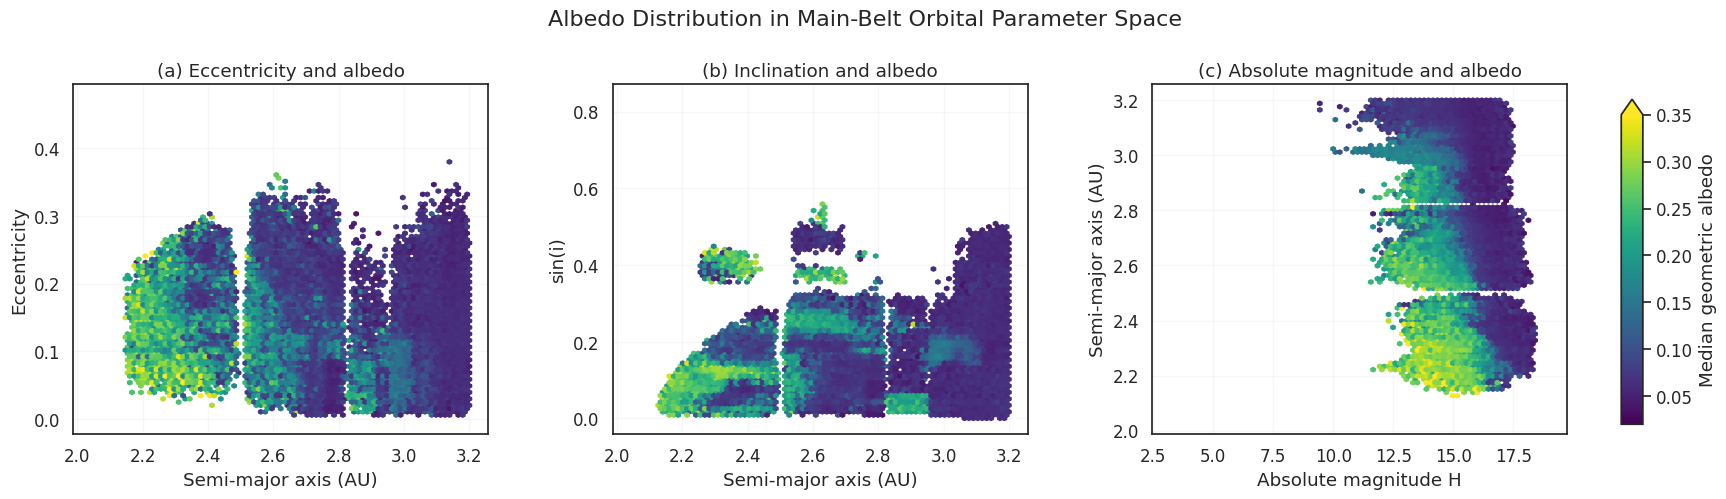

In [50]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plots = [
    ("a", "e", "Semi-major axis (AU)", "Eccentricity"),
    ("a", "sin_i", "Semi-major axis (AU)", "sin(i)"),
    ("H", "a", "Absolute magnitude H", "Semi-major axis (AU)")
]

for ax, (x, y, xlabel, ylabel) in zip(axes, plots):

    hb = ax.hexbin(
        df_clean[x],
        df_clean[y],
        C=df_clean["albedo"],
        reduce_C_function=np.median,
        gridsize=85,
        mincnt=5,
        cmap="viridis",
        vmin=0.02,
        vmax=0.35
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.15)

axes[0].set_title("(a) Eccentricity and albedo")
axes[1].set_title("(b) Inclination and albedo")
axes[2].set_title("(c) Absolute magnitude and albedo")

fig.suptitle(
    "Albedo Distribution in Main-Belt Orbital Parameter Space",
    fontsize=16
)

fig.subplots_adjust(
    left=0.06, right=0.89,
    bottom=0.13, top=0.83, wspace=0.30
)

cax = fig.add_axes([0.92, 0.15, 0.012, 0.65])

fig.colorbar(
    hb, cax=cax,
    label="Median geometric albedo",
    extend="max"
)

plt.savefig("orbital_albedo_relationships.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Orbital Parameters and Albedo

The hexbin plots show the median geometric albedo across orbital parameter space. Higher albedo values are more prominent in the inner main belt, while lower values dominate the outer regions.

These patterns motivate the use of orbital parameters and absolute magnitude as predictors in the classification models. Each displayed bin contains at least five observations.

## 5. FR-12 — Model Development

Three supervised classification models are developed to predict whether an asteroid is dark or non-dark.

### Input Features

- Semi-major axis (`a`)
- Eccentricity (`e`)
- Transformed inclination (`sin_i`)
- Absolute magnitude (`H`)

### Classification Models

1. **Logistic Regression:** Baseline classification model.
2. **Polynomial Logistic Regression:** Captures nonlinear relationships between features.
3. **Gradient Boosting:** Captures complex patterns and feature interactions.

The dataset is divided into 80% training and 20% testing using stratified sampling to preserve the target class distribution.

In [51]:

from sklearn.model_selection import train_test_split

# Input features and target
X = df_clean[["a", "e", "sin_i", "H"]]
y = df_clean["is_dark"]

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))


Training records: 98417
Testing records: 24605

Training class distribution:
is_dark
1    0.568
0    0.432
Name: proportion, dtype: float64


In [52]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Create the model pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Predictions on the test set
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate performance
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Logistic Regression Results
---------------------------
Accuracy: 0.7512
Balanced Accuracy: 0.7393
F1 Score: 0.7905
ROC-AUC: 0.8121

Confusion Matrix:
[[ 6932  3688]
 [ 2434 11551]]


In [53]:

from sklearn.preprocessing import PolynomialFeatures

# Create polynomial logistic regression model
poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train model
poly_model.fit(X_train, y_train)

# Predict
poly_pred = poly_model.predict(X_test)
poly_prob = poly_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Polynomial Logistic Regression Results")
print("--------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, poly_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, poly_pred), 4))
print("F1 Score:", round(f1_score(y_test, poly_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, poly_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, poly_pred))


Polynomial Logistic Regression Results
--------------------------------------
Accuracy: 0.7664
Balanced Accuracy: 0.7566
F1 Score: 0.8012
ROC-AUC: 0.8347

Confusion Matrix:
[[ 7271  3349]
 [ 2399 11586]]


In [54]:

from sklearn.ensemble import HistGradientBoostingClassifier

# Create Gradient Boosting model
gb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

# Make predictions
gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Gradient Boosting Results")
print("-------------------------")
print("Accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, gb_pred), 4))
print("F1 Score:", round(f1_score(y_test, gb_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, gb_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))


Gradient Boosting Results
-------------------------
Accuracy: 0.8049
Balanced Accuracy: 0.7974
F1 Score: 0.8324
ROC-AUC: 0.8772

Confusion Matrix:
[[ 7885  2735]
 [ 2065 11920]]


## 6. FR-13 — Model Evaluation

Model performance is assessed using stratified five-fold cross-validation and a held-out test dataset.

### Evaluation Metrics

- Accuracy
- Balanced accuracy
- F1-score
- ROC-AUC
- Confusion matrix

These metrics evaluate classification performance, generalization, and the ability to distinguish dark from non-dark asteroids.

In [55]:

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Polynomial Logistic": poly_model,
    "Gradient Boosting": gb_model
}

results = []

for name, model in models.items():
    print("Evaluating:", name)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "ROC-AUC": "roc_auc",
            "F1": "f1",
            "Balanced Accuracy": "balanced_accuracy"
        },
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Train ROC-AUC": scores["train_ROC-AUC"].mean(),
        "Validation ROC-AUC": scores["test_ROC-AUC"].mean(),
        "Overfitting Gap": (
            scores["train_ROC-AUC"].mean()
            - scores["test_ROC-AUC"].mean()
        ),
        "Validation F1": scores["test_F1"].mean(),
        "Validation Balanced Accuracy":
            scores["test_Balanced Accuracy"].mean()
    })

cv_results = pd.DataFrame(results)

display(cv_results.round(4))


Evaluating: Logistic Regression
Evaluating: Polynomial Logistic
Evaluating: Gradient Boosting


,Model,Train ROC-AUC,Validation ROC-AUC,Overfitting Gap,Validation F1,Validation Balanced Accuracy
0,Logistic Regression,0.8083,0.8083,0.0000,0.7872,0.7362
1,Polynomial Logistic,0.8315,0.8314,0.0001,0.7978,0.7528
2,Gradient Boosting,0.8865,0.8755,0.0110,0.8324,0.7981


### 6.1 Model Performance Comparison

| Model | Accuracy | Balanced Accuracy | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.7512 | 0.7393 | 0.7905 | 0.8121 |
| Polynomial Logistic Regression | 0.7664 | 0.7566 | 0.8012 | 0.8347 |
| Gradient Boosting | 0.8049 | 0.7974 | 0.8324 | 0.8772 |

### 6.2 Interpretation

Gradient Boosting achieves the highest performance across all four evaluation metrics. The improvement over logistic regression suggests that nonlinear relationships and feature interactions contribute to albedo prediction.

These results demonstrate that orbital characteristics and absolute magnitude contain useful information for distinguishing dark from non-dark asteroids.

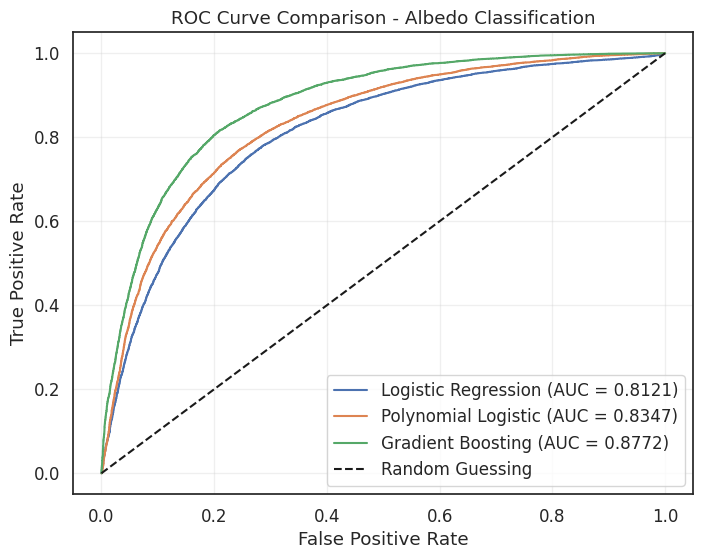

In [56]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

models = {
    "Logistic Regression": y_prob,
    "Polynomial Logistic": poly_prob,
    "Gradient Boosting": gb_prob
}

for name, probabilities in models.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Albedo Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

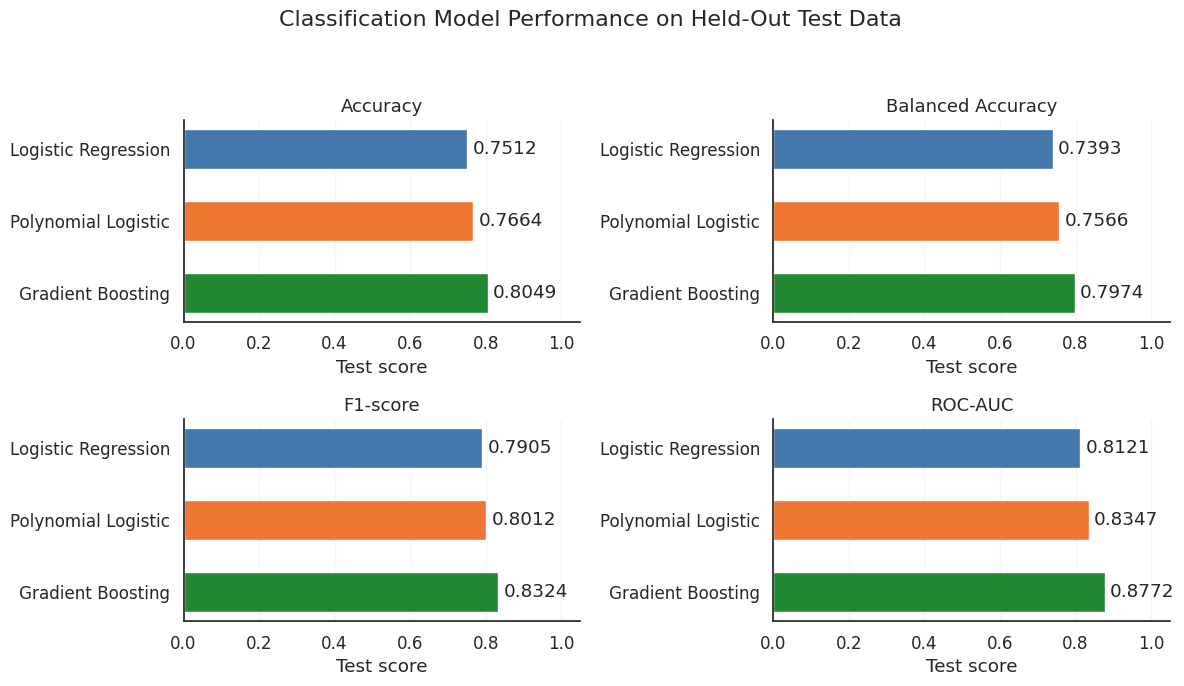

In [57]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

performance = pd.DataFrame({
    "Model": ["Logistic Regression",
              "Polynomial Logistic",
              "Gradient Boosting"],
    "Accuracy": [0.7512, 0.7664, 0.8049],
    "Balanced Accuracy": [0.7393, 0.7566, 0.7974],
    "F1-score": [0.7905, 0.8012, 0.8324],
    "ROC-AUC": [0.8121, 0.8347, 0.8772]
})

metrics = performance.columns[1:]
colors = ["#4477AA", "#EE7733", "#228833"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, metric in zip(axes.flat, metrics):

    bars = ax.barh(
        performance["Model"],
        performance[metric],
        color=colors,
        height=0.55
    )

    ax.bar_label(bars, fmt="%.4f", padding=4)
    ax.set_xlim(0, 1.05)
    ax.set_title(metric, fontsize=13)
    ax.set_xlabel("Test score")
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Classification Model Performance on Held-Out Test Data",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("model_performance_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

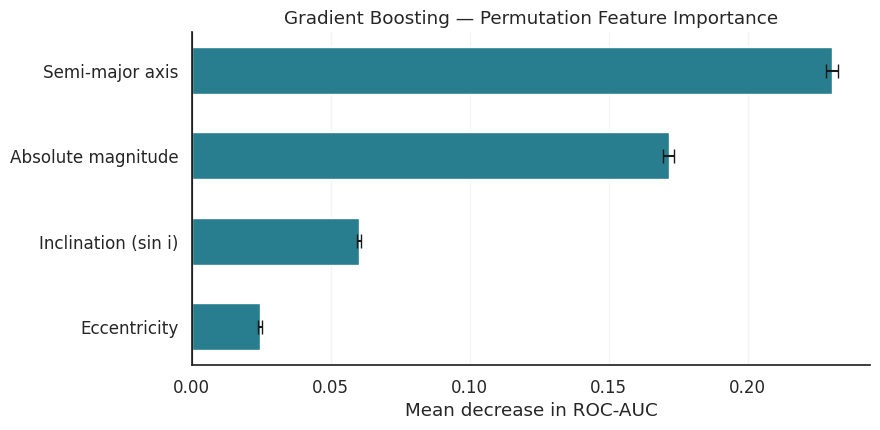

,Feature,Importance,Std
0,Semi-major axis,0.230291,0.002227
3,Absolute magnitude,0.171601,0.002050
2,Inclination (sin i),0.060278,0.000738
1,Eccentricity,0.024596,0.000685


In [58]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import pandas as pd

# Calculate feature importance on held-out test data
importance = permutation_importance(
    gb_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_names = {
    "a": "Semi-major axis",
    "e": "Eccentricity",
    "sin_i": "Inclination (sin i)",
    "H": "Absolute magnitude"
}

importance_df = pd.DataFrame({
    "Feature": [feature_names.get(c, c) for c in X_test.columns],
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance")

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"],
    color="#287D8E",
    capsize=5,
    height=0.55
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean decrease in ROC-AUC")
ax.set_title("Gradient Boosting — Permutation Feature Importance")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("gradient_boosting_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

display(importance_df.sort_values("Importance", ascending=False))

### 6.3 Feature Importance

Permutation importance identifies semi-major axis as the most influential predictor, followed by absolute magnitude, inclination, and eccentricity. Error bars represent the standard deviation across ten permutations.

These findings are consistent with the observed albedo patterns across the main asteroid belt.

## 7. FR-14 — Spectral Complex Analysis

This section examines the relationship between asteroid spectral classifications and geometric albedo.

Bus spectral classifications are grouped into five broad complexes (C, D, S, V, and X) using a simplified first-letter mapping. The distribution of dark, medium, and light asteroids is compared across these groups to identify differences in surface reflectivity.

In [59]:
import pandas as pd

# Use Bus spectral types where available
spectral = df_clean.dropna(subset=["spec_B"]).copy()

# Group related spectral subtypes
spectral["complex"] = spectral["spec_B"].str.strip().str[0]

# Keep the required complexes
spectral = spectral[
    spectral["complex"].isin(["C", "S", "X", "V", "D"])
].copy()

# Compare spectral complexes with albedo categories
comparison = pd.crosstab(
    spectral["complex"],
    spectral["albedo_category"]
)

comparison["Total"] = comparison.sum(axis=1)

print("Spectral complex vs albedo category:")
display(comparison)

print("\nPercentage within each complex:")
display(
    pd.crosstab(
        spectral["complex"],
        spectral["albedo_category"],
        normalize="index"
    ).mul(100).round(1)
)

Spectral complex vs albedo category:


albedo_category,Dark,Light,Medium,Total
complex,,,,
C,278,3,34,315
D,5,0,1,6
S,3,118,340,461
V,0,21,7,28
X,95,11,97,203



Percentage within each complex:


albedo_category,Dark,Light,Medium
complex,,,
C,88.3,1.0,10.8
D,83.3,0.0,16.7
S,0.7,25.6,73.8
V,0.0,75.0,25.0
X,46.8,5.4,47.8


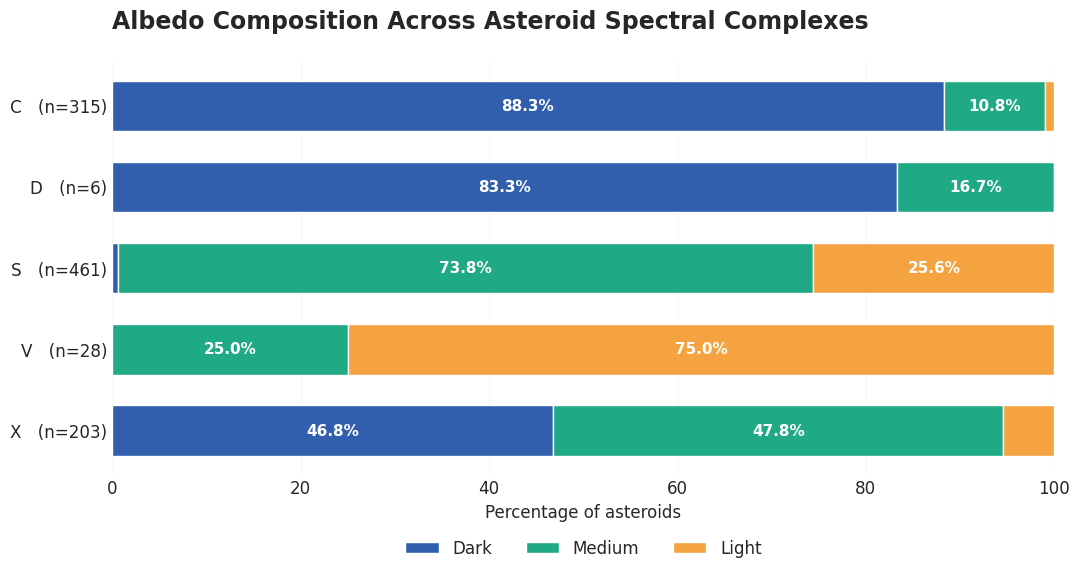

In [60]:
import matplotlib.pyplot as plt
import pandas as pd

pct = pd.crosstab(
    spectral["complex"],
    spectral["albedo_category"],
    normalize="index"
).mul(100)

pct = pct[["Dark", "Medium", "Light"]]
counts = spectral["complex"].value_counts()

colors = ["#315FAD", "#20A985", "#F4A340"]

fig, ax = plt.subplots(figsize=(11, 6))
left = pd.Series(0.0, index=pct.index)

for category, color in zip(pct.columns, colors):
    values = pct[category]

    bars = ax.barh(
        pct.index,
        values,
        left=left,
        color=color,
        height=0.62,
        label=category
    )

    for bar, value, start in zip(bars, values, left):
        if value >= 8:
            ax.text(
                start + value / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=11,
                fontweight="bold"
            )

    left += values

ax.set_yticks(range(len(pct)))
ax.set_yticklabels([
    f"{name}   (n={counts[name]})"
    for name in pct.index
])

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of asteroids", fontsize=12)

ax.set_title(
    "Albedo Composition Across Asteroid Spectral Complexes",
    fontsize=17,
    fontweight="bold",
    loc="left",
    pad=24
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="both", length=0)
ax.grid(axis="x", alpha=0.12)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

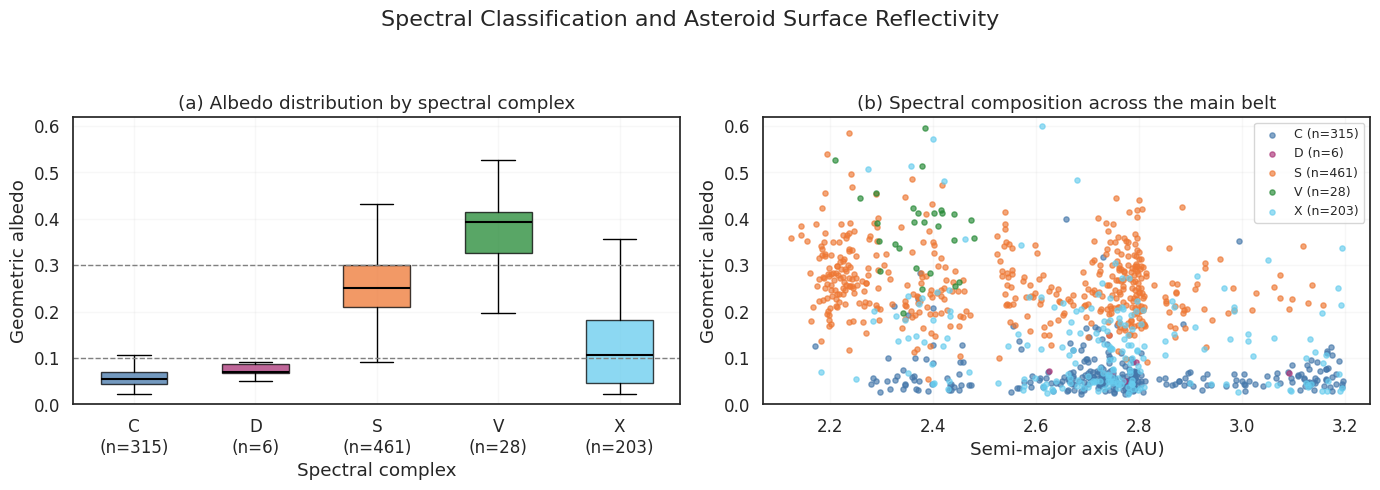

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

spectral = df_clean.dropna(subset=["spec_B"]).copy()
spectral["complex"] = spectral["spec_B"].str[0].str.upper()

groups = ["C", "D", "S", "V", "X"]
colors = ["#4477AA", "#AA3377", "#EE7733", "#228833", "#66CCEE"]

spectral = spectral[spectral["complex"].isin(groups)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A. Albedo distribution by spectral complex
data = [
    spectral.loc[spectral["complex"] == g, "albedo"]
    for g in groups
]

bp = axes[0].boxplot(
    data,
    patch_artist=True,
    showfliers=False,
    widths=0.55,
    medianprops=dict(color="black", linewidth=1.5)
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

axes[0].set_xticks(range(1, 6))
axes[0].set_xticklabels([
    f"{g}\n(n={len(d)})"
    for g, d in zip(groups, data)
])

axes[0].axhline(0.10, linestyle="--",
                color="gray", linewidth=1)

axes[0].axhline(0.30, linestyle="--",
                color="gray", linewidth=1)

axes[0].set_xlabel("Spectral complex")
axes[0].set_ylabel("Geometric albedo")
axes[0].set_title("(a) Albedo distribution by spectral complex")

# B. Orbital location and spectral composition
for group, color in zip(groups, colors):

    subset = spectral[spectral["complex"] == group]

    axes[1].scatter(
        subset["a"],
        subset["albedo"],
        s=14,
        alpha=0.65,
        color=color,
        label=f"{group} (n={len(subset)})"
    )

axes[1].set_xlabel("Semi-major axis (AU)")
axes[1].set_ylabel("Geometric albedo")
axes[1].set_title("(b) Spectral composition across the main belt")
axes[1].legend(fontsize=9)

for ax in axes:
    ax.set_ylim(0, 0.62)
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)

fig.suptitle(
    "Spectral Classification and Asteroid Surface Reflectivity",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("FR14_spectral_analysis.png",
            dpi=300, bbox_inches="tight")
plt.show()

### 7.1 Results and Interpretation

- **C-complex:** Predominantly dark asteroids (88.3%).
- **S-complex:** Predominantly medium-albedo asteroids (73.8%).
- **V-complex:** Predominantly light asteroids (75.0%).
- **X-complex:** Mixed albedo distribution.
- **D-complex:** Predominantly dark, but the small sample size limits interpretation.

The results indicate an association between spectral classification and surface reflectivity. However, limited spectral coverage and unequal sample sizes should be considered when interpreting these findings.

In [62]:
import pandas as pd

df_full["a"] = pd.to_numeric(
    df_full["a"], errors="coerce"
)

print(df_full["a"].describe())

count    825292.000000
mean          2.696631
std           0.298779
min           2.000000
25%           2.425000
50%           2.670000
75%           2.995000
max           3.200000
Name: a, dtype: float64


## 8. FR-15 — Orbital Population Analysis

This section compares geometric albedo across four asteroid populations:

- **Main-belt asteroids (MBA)**
- **Mars-crossing asteroids (MCA)**
- **Near-Earth asteroids (NEO)**
- **Jupiter Trojans (TJN)**

Additional asteroid records are retrieved from the NASA/JPL database and combined with the original main-belt dataset. Mean and median albedo values are compared across the four populations to investigate differences in surface reflectivity.

In [63]:
import requests
import pandas as pd

url = "https://ssd-api.jpl.nasa.gov/sbdb_query.api"
fields = "pdes,class,a,e,i,H,albedo"

datasets = []

for asteroid_class in ["MCA", "IEO", "ATE", "APO", "AMO", "TJN"]:

    params = {
        "fields": fields,
        "sb-kind": "a",
        "sb-class": asteroid_class
    }

    response = requests.get(url, params=params, timeout=120)
    response.raise_for_status()

    result = response.json()

    data = pd.DataFrame(
        result.get("data", []),
        columns=result["fields"]
    )

    datasets.append(data)

    print(f"{asteroid_class}: {len(data):,} asteroids")

df_other = pd.concat(datasets, ignore_index=True)

for col in ["a", "e", "i", "H", "albedo"]:
    df_other[col] = pd.to_numeric(
        df_other[col], errors="coerce"
    )

print("\nTotal additional asteroids:", len(df_other))
print("\nAsteroids with measured albedo:")
print(df_other.groupby("class")["albedo"].count())

df_other.to_csv("additional_asteroid_classes.csv", index=False)

MCA: 30,659 asteroids
IEO: 39 asteroids
ATE: 3,515 asteroids
APO: 24,570 asteroids
AMO: 15,041 asteroids
TJN: 16,676 asteroids

Total additional asteroids: 90500

Asteroids with measured albedo:
class
AMO     335
APO     745
ATE     125
IEO       0
MCA     598
TJN    1879
Name: albedo, dtype: int64


In [64]:
# Combine main-belt and additional asteroid data
df_all = pd.concat(
    [df_full, df_other],
    ignore_index=True
)

# Convert albedo to numeric
df_all["albedo"] = pd.to_numeric(
    df_all["albedo"], errors="coerce"
)
# Apply consistent albedo validity limits
df_all["albedo"] = df_all["albedo"].where(
    df_all["albedo"].between(0.02, 0.60)
)

# Group near-Earth subclasses together
neo_classes = ["IEO", "ATE", "APO", "AMO"]

df_all["orbit_group"] = df_all["class"].replace({
    "IEO": "NEO",
    "ATE": "NEO",
    "APO": "NEO",
    "AMO": "NEO",
    "MBA": "Main Belt",
    "MCA": "Mars Crossing",
    "TJN": "Jupiter Trojan"
})

# Calculate statistics
orbit_summary = (
    df_all.groupby("orbit_group")
    .agg(
        total_asteroids=("pdes", "count"),
        albedo_measurements=("albedo", "count"),
        mean_albedo=("albedo", "mean"),
        median_albedo=("albedo", "median")
    )
    .round(3)
)

display(orbit_summary)

,total_asteroids,albedo_measurements,mean_albedo,median_albedo
orbit_group,,,,
Jupiter Trojan,16676,1875,0.074,0.070
Main Belt,825292,123022,0.134,0.081
Mars Crossing,30659,593,0.203,0.144
NEO,43165,1133,0.177,0.145


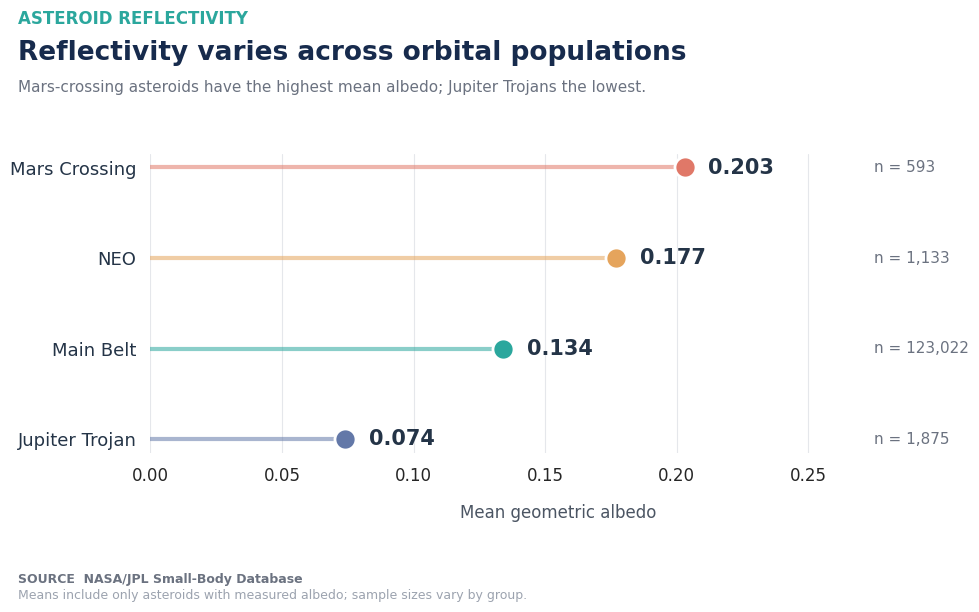

In [65]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data
order = ["Mars Crossing", "NEO", "Main Belt", "Jupiter Trojan"]
data = orbit_summary.loc[order]

colors = ["#E07868", "#E5A45C", "#2BA79D", "#6378A8"]

fig, ax = plt.subplots(figsize=(12, 6.5), facecolor="white")
ax.set_facecolor("white")

y = np.arange(len(order))

# Plot lines and markers
for i, (group, color) in enumerate(zip(order, colors)):
    value = data.loc[group, "mean_albedo"]
    count = int(data.loc[group, "albedo_measurements"])

    ax.hlines(
        y=i,
        xmin=0,
        xmax=value,
        color=color,
        linewidth=3,
        alpha=0.55
    )

    ax.scatter(
        value,
        i,
        s=230,
        color=color,
        edgecolor="white",
        linewidth=2,
        zorder=3
    )

    ax.text(
        value + 0.009,
        i,
        f"{value:.3f}",
        va="center",
        fontsize=15,
        fontweight="bold",
        color="#243447"
    )

    ax.text(
        0.275,
        i,
        f"n = {count:,}",
        va="center",
        fontsize=11,
        color="#6B7280"
    )

# Axes
ax.set_yticks(y)
ax.set_yticklabels(order, fontsize=13, color="#243447")
ax.invert_yaxis()

ax.set_xlim(0, 0.31)
ax.set_xticks(np.arange(0, 0.26, 0.05))

ax.set_xlabel(
    "Mean geometric albedo",
    fontsize=12,
    color="#4B5563",
    labelpad=14
)

ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="both", length=0, pad=10)

# Title
fig.text(
    0.13, 0.96,
    "ASTEROID REFLECTIVITY",
    fontsize=12,
    fontweight="bold",
    color="#2BA79D"
)

fig.text(
    0.13, 0.905,
    "Reflectivity varies across orbital populations",
    fontsize=19,
    fontweight="bold",
    color="#172B4D"
)

fig.text(
    0.13, 0.855,
    "Mars-crossing asteroids have the highest mean albedo; Jupiter Trojans the lowest.",
    fontsize=11,
    color="#6B7280"
)

# Source notes
fig.text(
    0.13, 0.10,
    "SOURCE  NASA/JPL Small-Body Database",
    fontsize=9,
    fontweight="bold",
    color="#6B7280"
)

fig.text(
    0.13, 0.075,
    "Means include only asteroids with measured albedo; sample sizes vary by group.",
    fontsize=9,
    color="#9CA3AF"
)

# Layout
plt.subplots_adjust(
    left=0.24,
    right=0.92,
    top=0.76,
    bottom=0.30
)

# Save high-resolution chart
plt.savefig(
    "FR15_albedo_comparison_final.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

/tmp/ipykernel_417/2520423219.py:118: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/tmp/ipykernel_417/2520423219.py:120: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


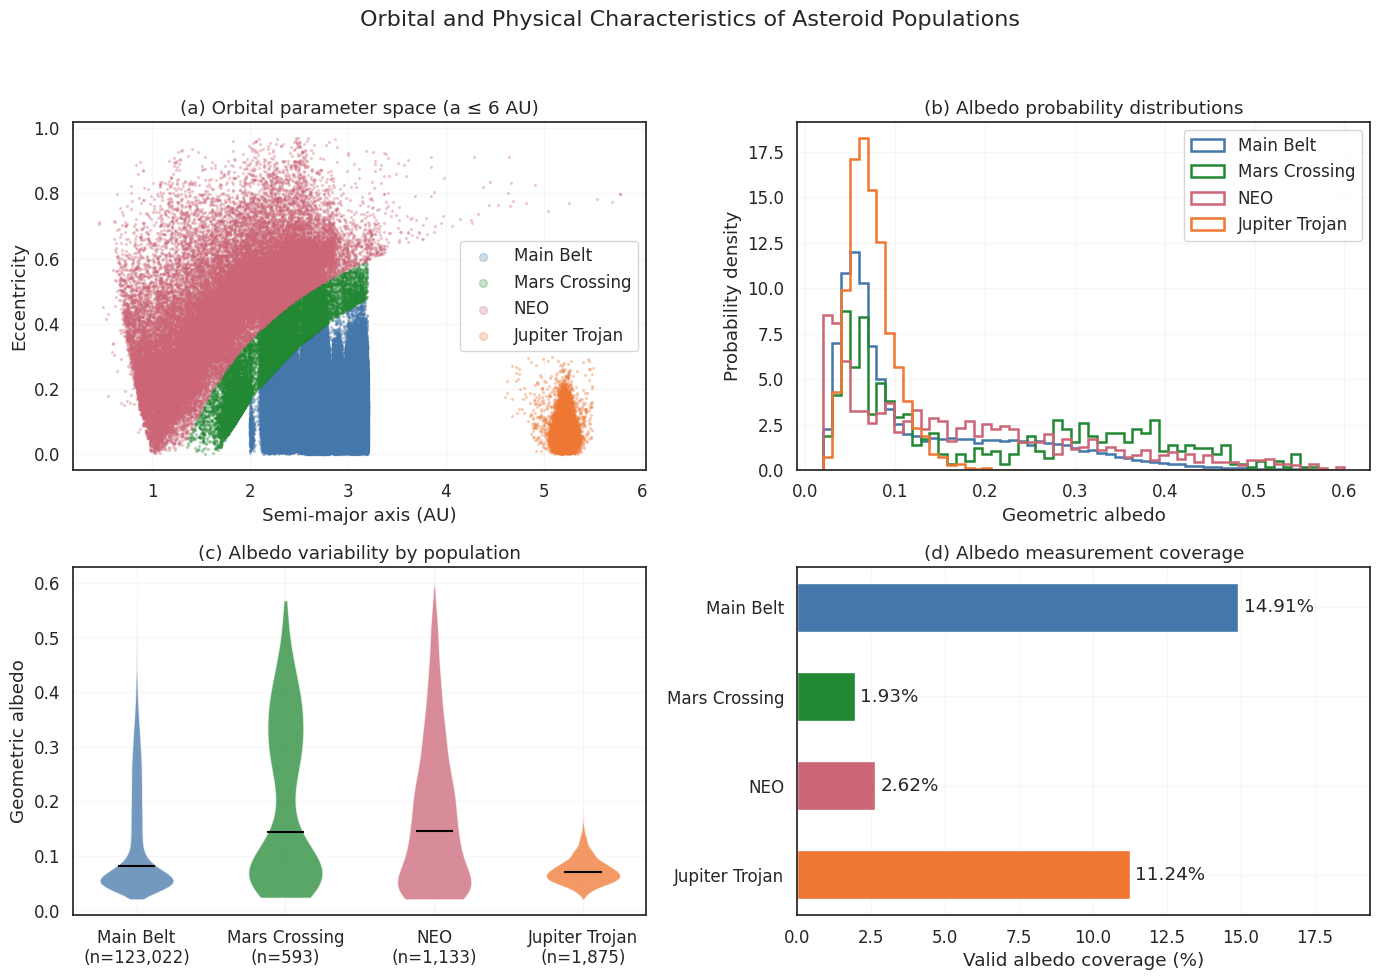

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

population = df_all.copy()

for col in ["a", "e", "albedo"]:
    population[col] = pd.to_numeric(
        population[col], errors="coerce"
    )

groups = ["Main Belt", "Mars Crossing", "NEO", "Jupiter Trojan"]
colors = ["#4477AA", "#228833", "#CC6677", "#EE7733"]

population = population[
    population["orbit_group"].isin(groups)
]

measured = population[
    population["albedo"].between(0.02, 0.60)
].copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# A. Orbital distribution
for group, color in zip(groups, colors):
    subset = population[
        (population["orbit_group"] == group) &
        population["a"].between(0, 6)
    ]

    axes[0, 0].scatter(
        subset["a"], subset["e"],
        s=2, alpha=0.25, color=color,
        label=group, rasterized=True
    )

axes[0, 0].set_xlabel("Semi-major axis (AU)")
axes[0, 0].set_ylabel("Eccentricity")
axes[0, 0].set_title("(a) Orbital parameter space (a ≤ 6 AU)")
axes[0, 0].legend(markerscale=4)

# B. Normalized albedo distributions
for group, color in zip(groups, colors):
    subset = measured[measured["orbit_group"] == group]

    axes[0, 1].hist(
        subset["albedo"],
        bins=np.linspace(0.02, 0.60, 60),
        density=True,
        histtype="step",
        linewidth=1.8,
        color=color,
        label=group
    )

axes[0, 1].set_xlabel("Geometric albedo")
axes[0, 1].set_ylabel("Probability density")
axes[0, 1].set_title("(b) Albedo probability distributions")
axes[0, 1].legend()

# C. Albedo variability
data = [
    measured.loc[
        measured["orbit_group"] == g, "albedo"
    ].values
    for g in groups
]

vp = axes[1, 0].violinplot(
    data,
    showmedians=True,
    showextrema=False
)

for body, color in zip(vp["bodies"], colors):
    body.set_facecolor(color)
    body.set_alpha(0.75)

vp["cmedians"].set_color("black")

axes[1, 0].set_xticks(range(1, 5))
axes[1, 0].set_xticklabels([
    f"{g}\n(n={len(d):,})"
    for g, d in zip(groups, data)
])

axes[1, 0].set_ylabel("Geometric albedo")
axes[1, 0].set_title("(c) Albedo variability by population")

# D. Valid albedo measurement coverage
coverage = [
    100 * len(measured[measured["orbit_group"] == g]) /
    len(population[population["orbit_group"] == g])
    for g in groups
]

bars = axes[1, 1].barh(
    groups, coverage,
    color=colors, height=0.55
)

axes[1, 1].bar_label(bars, fmt="%.2f%%", padding=4)
axes[1, 1].set_xlim(0, max(coverage) * 1.3)
axes[1, 1].set_xlabel("Valid albedo coverage (%)")
axes[1, 1].set_title("(d) Albedo measurement coverage")
axes[1, 1].invert_yaxis()

for ax in axes.flat:
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)

fig.suptitle(
    "Orbital and Physical Characteristics of Asteroid Populations",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "FR15_population_scientific_analysis.png",
    dpi=300, bbox_inches="tight"
)

plt.show()

### 8.1 Results and Interpretation

| Orbital Population | Mean Albedo | Median Albedo |
|---|---:|---:|
| Jupiter Trojan | 0.074 | 0.070 |
| Main Belt | 0.134 | 0.081 |
| Mars Crossing | 0.203 | 0.144 |
| Near-Earth Objects (NEO) | 0.177 | 0.145 |

Jupiter Trojans exhibit the lowest mean and median albedo,
indicating predominantly dark surfaces. Mars Crossing
asteroids have the highest mean albedo, while Near-Earth
Objects exhibit a similar median albedo.

These results suggest differences in surface reflectivity
across orbital populations. However, differences in sample
sizes and albedo measurement coverage may introduce
observational bias.

Only asteroids with geometric albedo values between
0.02 and 0.60 were included in the albedo comparison.
The top-down orbital visualization is schematic and does
not represent actual asteroid positions.

In [67]:
print(df_all.groupby("orbit_group")["a"].agg(["min", "max", "count"]))

                   min      max   count
orbit_group                            
Jupiter Trojan  4.6040    5.499   16676
Main Belt       2.0000    3.200  825292
Mars Crossing   1.3520    3.199   30659
NEO             0.4618  353.800   43165


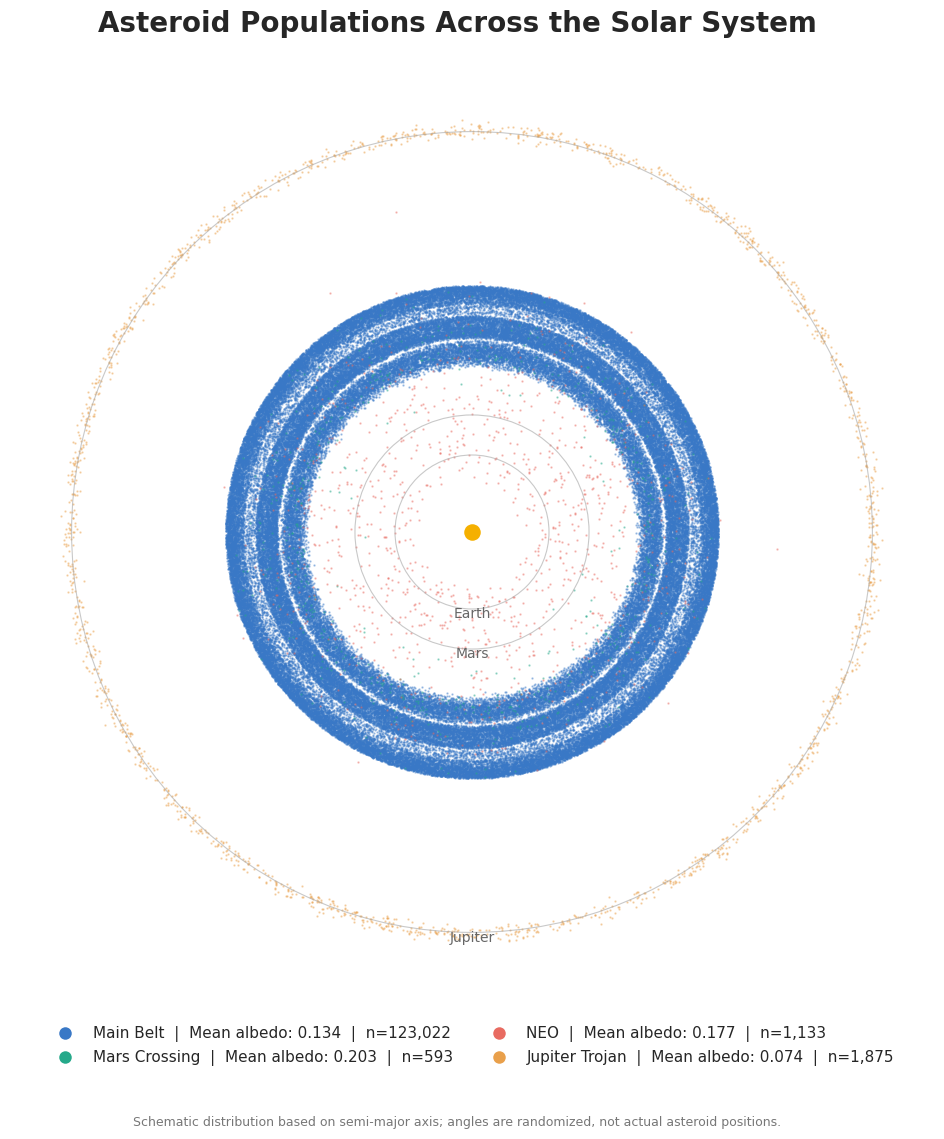

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Prepare data for visualization
plot_data = df_all.dropna(subset=["a", "albedo"]).copy()

# Keep asteroids within the displayed orbital range
plot_data = plot_data[
    plot_data["a"].between(0, 6)
].copy()

# Random angles for a schematic orbital view
rng = np.random.default_rng(42)
theta = rng.uniform(0, 2 * np.pi, len(plot_data))

plot_data["x"] = plot_data["a"] * np.cos(theta)
plot_data["y"] = plot_data["a"] * np.sin(theta)

# Colors
colors = {
    "Main Belt": "#3978C6",
    "Mars Crossing": "#25A98A",
    "NEO": "#E86B61",
    "Jupiter Trojan": "#E9A04B"
}

# Create figure
fig, ax = plt.subplots(figsize=(12, 12), facecolor="white")

# Plot orbital groups
for group, color in colors.items():

    subset = plot_data[
        plot_data["orbit_group"] == group
    ]

    ax.scatter(
        subset["x"],
        subset["y"],
        s=0.5,
        alpha=0.4,
        color=color,
        rasterized=True
    )

# Sun
ax.scatter(
    0, 0,
    s=180,
    color="#F5B000",
    edgecolor="white",
    linewidth=1.5,
    zorder=5
)

# Reference orbital distances
for radius, name in [(1.0, "Earth"), (1.52, "Mars"), (5.2, "Jupiter")]:

    circle = plt.Circle(
        (0, 0),
        radius,
        fill=False,
        edgecolor="#A5A5A5",
        linewidth=0.8,
        alpha=0.6
    )

    ax.add_patch(circle)

    ax.text(
        0,
        -radius - 0.12,
        name,
        ha="center",
        fontsize=10,
        color="#666666"
    )

# Formatting
ax.set_aspect("equal")
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.axis("off")

# Legend with group statistics
legend_items = []

for group, color in colors.items():

    row = orbit_summary.loc[group]

    legend_items.append(
        Line2D(
            [0], [0],
            marker="o",
            linestyle="none",
            markerfacecolor=color,
            markeredgecolor="none",
            markersize=9,
            label=(
                f"{group}  |  "
                f"Mean albedo: {row['mean_albedo']:.3f}  |  "
                f"n={int(row['albedo_measurements']):,}"
            )
        )
    )

fig.suptitle(
    "Asteroid Populations Across the Solar System",
    fontsize=20,
    fontweight="bold",
    y=0.97
)

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
    fontsize=11
)

fig.text(
    0.5, 0.04,
    "Schematic distribution based on semi-major axis; angles are randomized, not actual asteroid positions.",
    ha="center",
    fontsize=9,
    color="#777777"
)

plt.subplots_adjust(
    top=0.92,
    bottom=0.15
)

plt.savefig(
    "FR15_topdown_orbital_populations.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 9. Conclusions and Limitations

### Key Findings

- Gradient Boosting achieved the best classification performance, with an accuracy of 80.49% and a ROC-AUC of 0.8772.
- Spectral classifications show distinct patterns in albedo distribution.
- Jupiter Trojans exhibit lower mean albedo than the other orbital populations analyzed.

### Limitations

- Only 14.9% of the original main-belt dataset was retained for classification.
- Limited spectral coverage and unequal sample sizes may introduce selection bias.
- The orbital population visualization represents a schematic distribution rather than actual asteroid positions.